In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model

DATA_PATH  = "/home/aqsa/sok/breast.csv"
MODELS_DIR = "/home/aqsa/sok/models_breast"
TARGET     = "diagnosis"
RANDOM_STATE = 42

In [ ]:
df = pd.read_csv(DATA_PATH)
drop_cols = [c for c in ['id', 'Unnamed: 32'] if c in df.columns]
df = df.drop(columns=drop_cols)
df[TARGET] = LabelEncoder().fit_transform(df[TARGET])   # B=0, M=1

feature_names = [c for c in df.columns if c != TARGET]
X = df[feature_names].values.astype(np.float32)
y = df[TARGET].astype(int).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

lstm = load_model(os.path.join(MODELS_DIR, "LSTM_run0.h5"), compile=False)
ebm  = joblib.load(os.path.join(MODELS_DIR, "EBM_run0.joblib"))

print(f"Features: {len(feature_names)} | Test set: {X_test.shape}")
print(f"Class names: 0=Benign, 1=Malignant")

Features: 30 | Test set: (114, 30)
Class names: 0=Benign, 1=Malignant


In [ ]:
def lstm_predict_proba(X):
    if X.ndim == 1: X = X.reshape(1, -1)
    X3d = X.reshape(X.shape[0], 1, X.shape[1])
    p1 = lstm.predict(X3d, verbose=0).flatten()
    p1 = np.clip(p1, 1e-7, 1 - 1e-7)
    return np.column_stack([1 - p1, p1])

# SHAP — KernelExplainer on LSTM
shap_explainer = shap.KernelExplainer(lstm_predict_proba, X_train[:50])

# LIME — on LSTM
lime_explainer = LimeTabularExplainer(
    X_train[:50], feature_names=feature_names,
    class_names=["Benign", "Malignant"],
    discretize_continuous=True, random_state=RANDOM_STATE,
)

def get_shap_attributions(x):
    sv = shap_explainer.shap_values(x.reshape(1, -1), nsamples=200, silent=True)
    if isinstance(sv, list):
        return np.asarray(sv[1][0] if len(sv) > 1 else sv[0][0]).flatten()
    arr = np.asarray(sv)
    if arr.ndim == 3: return arr[0, :, 1].flatten()
    if arr.ndim == 2: return arr[0].flatten()
    return arr.flatten()

def get_lime_attributions(x):
    exp = lime_explainer.explain_instance(
        x.flatten(), lstm_predict_proba,
        num_features=len(feature_names), num_samples=500,
    )
    d = dict(exp.as_list())
    out = np.zeros(len(feature_names))
    for i, fn in enumerate(feature_names):
        for lf, w in d.items():
            if fn in lf:
                out[i] = w
                break
    return out

def get_ebm_attributions(x):
    x_df = pd.DataFrame(x.reshape(1, -1), columns=feature_names)
    local = ebm.explain_local(x_df)
    d = local.data(0)
    if isinstance(d, dict) and "scores" in d:
        arr = np.asarray(d["scores"])
        return arr[:len(feature_names)]
    return np.zeros(len(feature_names))

In [ ]:
def plot_pos_neg(attributions, feature_names, title, top_n=12, ax=None):
    """Horizontal bar chart: positive (toward Malignant) red, negative (toward Benign) blue."""
    attr = np.asarray(attributions).flatten()
    # take top_n by absolute magnitude
    idx = np.argsort(np.abs(attr))[::-1][:top_n]
    idx = idx[np.argsort(attr[idx])]          # sort by signed value for display
    vals = attr[idx]
    names = [feature_names[i] for i in idx]
    colors = ['#d62728' if v > 0 else '#1f77b4' for v in vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(range(len(vals)), vals, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(names, fontsize=9)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel("Attribution  (← Benign | Malignant →)", fontsize=9)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    return ax

Benign sample    -> test index 0
Malignant sample -> test index 1

Computing attributions (SHAP slowest, ~40-80s total)...
  done class 0 (Benign)
  done class 1 (Malignant)


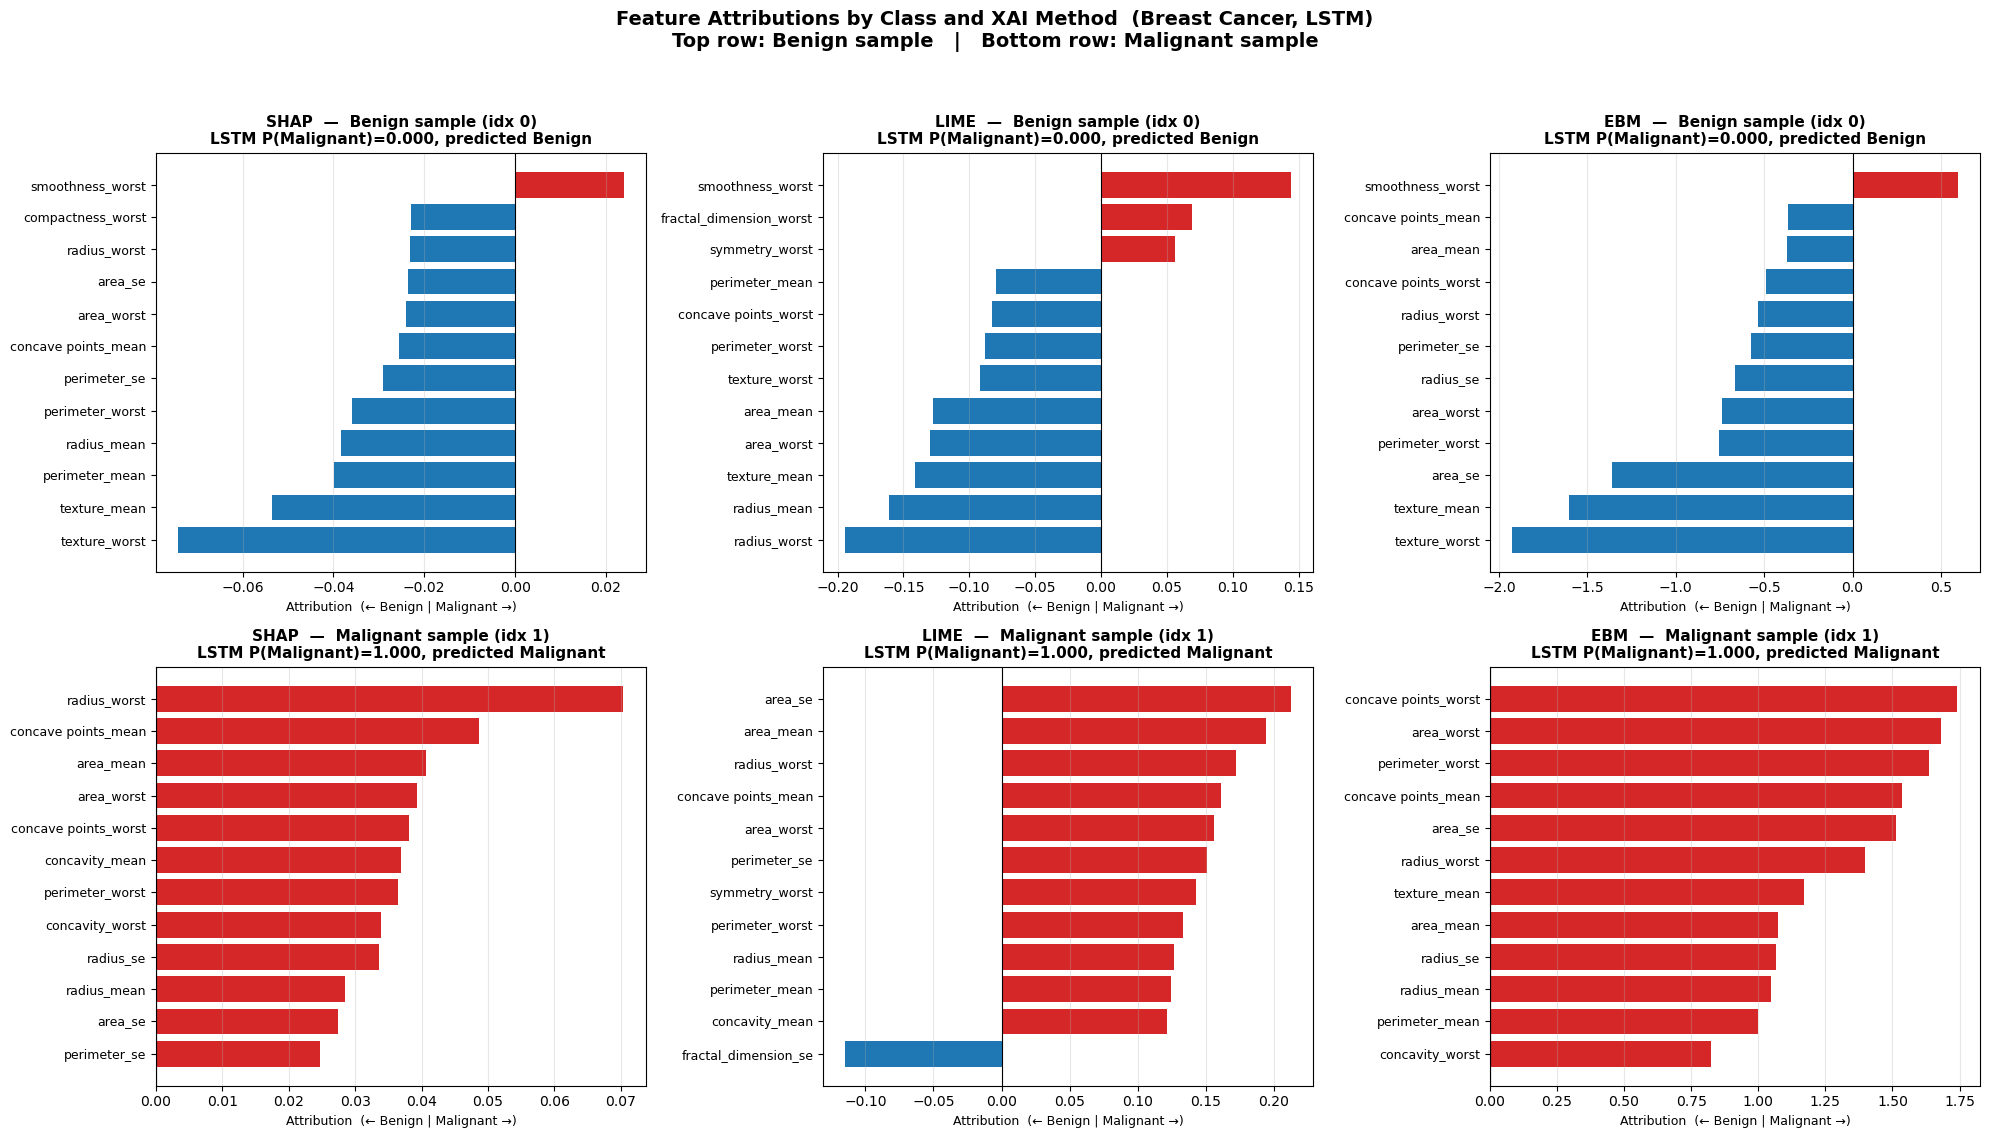


Saved: breast_xai_both_classes.png


In [ ]:
# Pick one representative sample from each class (correctly classified)
def pick_sample(target_class):
    """Return index of a test sample of `target_class` that the LSTM also predicts correctly."""
    candidates = np.where(y_test == target_class)[0]
    for idx in candidates:
        p = lstm_predict_proba(X_test[idx])[0]
        if int(p[1] > 0.5) == target_class:
            return idx
    return candidates[0]   # fallback: first of that class even if misclassified

benign_idx    = pick_sample(0)   # class 0 = Benign
malignant_idx = pick_sample(1)   # class 1 = Malignant

label_names = {0: "Benign", 1: "Malignant"}

print(f"Benign sample    -> test index {benign_idx}")
print(f"Malignant sample -> test index {malignant_idx}")

# Compute attributions for both samples, all three methods
samples = {0: X_test[benign_idx], 1: X_test[malignant_idx]}
sample_idx = {0: benign_idx, 1: malignant_idx}

print("\nComputing attributions (SHAP slowest, ~40-80s total)...")
attributions = {}
for cls, x in samples.items():
    attributions[cls] = {
        "SHAP": get_shap_attributions(x),
        "LIME": get_lime_attributions(x),
        "EBM":  get_ebm_attributions(x),
    }
    print(f"  done class {cls} ({label_names[cls]})")

# 2x3 grid: rows = classes, columns = methods
methods = ["SHAP", "LIME", "EBM"]
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for row, cls in enumerate([0, 1]):
    x = samples[cls]
    pred_proba = lstm_predict_proba(x)[0]
    pred_label = int(pred_proba[1] > 0.5)
    for col, method in enumerate(methods):
        title = (f"{method}  —  {label_names[cls]} sample (idx {sample_idx[cls]})\n"
                 f"LSTM P(Malignant)={pred_proba[1]:.3f}, predicted {label_names[pred_label]}")
        plot_pos_neg(attributions[cls][method], feature_names, title, ax=axes[row, col])

plt.suptitle(
    "Feature Attributions by Class and XAI Method  (Breast Cancer, LSTM)\n"
    "Top row: Benign sample   |   Bottom row: Malignant sample",
    fontsize=14, fontweight='bold', y=1.03,
)
plt.tight_layout()
plt.savefig("/home/aqsa/sok/breast_xai_both_classes.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: breast_xai_both_classes.png")

Benign idx=0, Malignant idx=1
  class 0 / SHAP: shape=(30,), range=[-0.0663, 0.0189]
  class 0 / LIME: shape=(30,), range=[-0.1463, 0.1909]
  class 0 / EBM: shape=(30,), range=[-1.9253, 0.5945]
  class 1 / SHAP: shape=(30,), range=[0.0000, 0.0880]
  class 1 / LIME: shape=(30,), range=[-0.1299, 0.2070]
  class 1 / EBM: shape=(30,), range=[-0.4474, 1.7393]


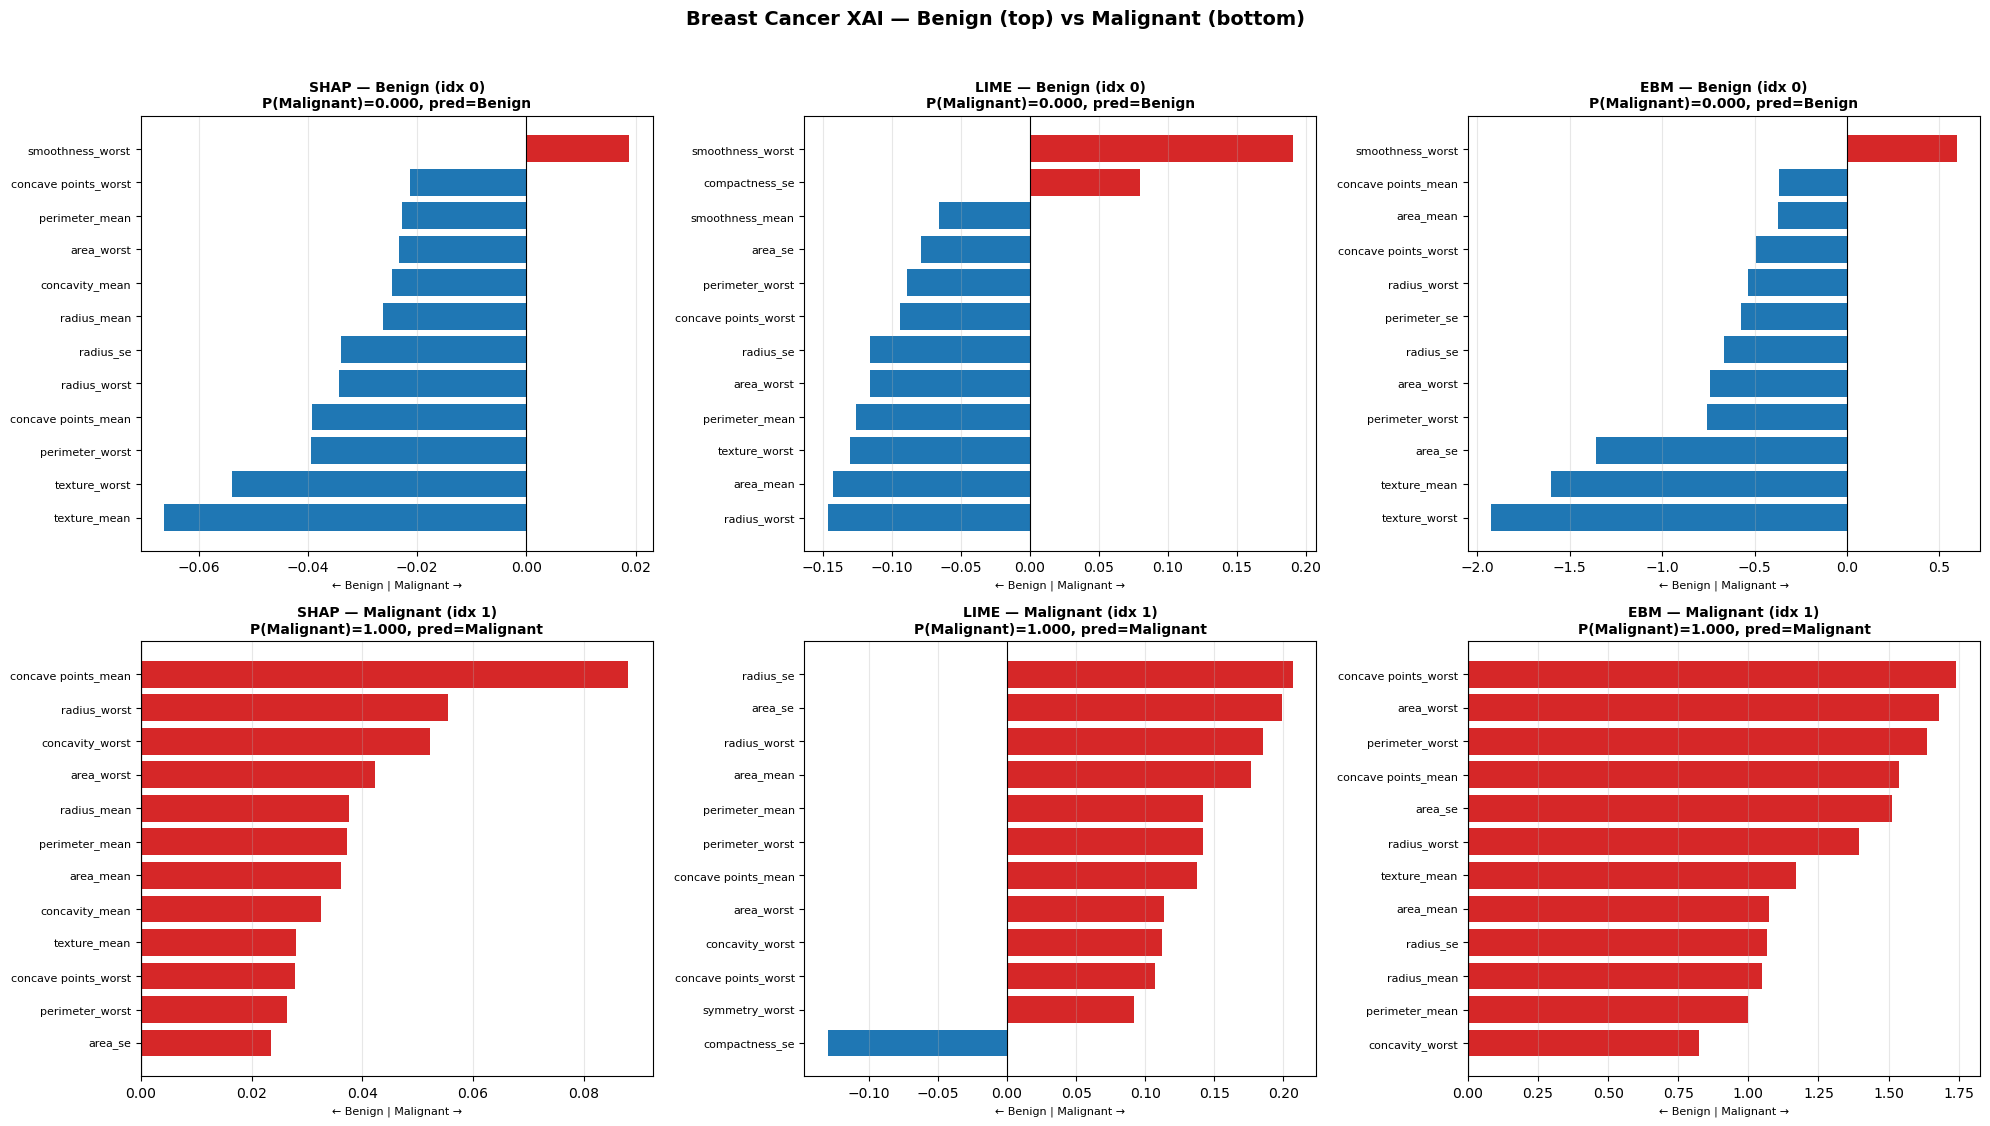


Saved: breast_xai_both_classes.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- pick one correctly-classified sample per class ---
def pick_sample(target_class):
    candidates = np.where(y_test == target_class)[0]
    for idx in candidates:
        p = lstm_predict_proba(X_test[idx])[0]
        if int(p[1] > 0.5) == target_class:
            return idx
    return candidates[0]

benign_idx    = pick_sample(0)
malignant_idx = pick_sample(1)
label_names = {0: "Benign", 1: "Malignant"}
print(f"Benign idx={benign_idx}, Malignant idx={malignant_idx}")

samples    = {0: X_test[benign_idx], 1: X_test[malignant_idx]}
sample_idx = {0: benign_idx, 1: malignant_idx}

# --- compute all 6 attribution vectors, report as we go ---
methods = ["SHAP", "LIME", "EBM"]
fns = {"SHAP": get_shap_attributions,
       "LIME": get_lime_attributions,
       "EBM":  get_ebm_attributions}

attributions = {0: {}, 1: {}}
for cls in [0, 1]:
    for method in methods:
        try:
            a = np.asarray(fns[method](samples[cls])).flatten()
            attributions[cls][method] = a
            print(f"  class {cls} / {method}: shape={a.shape}, "
                  f"range=[{a.min():.4f}, {a.max():.4f}]")
        except Exception as ex:
            print(f"  class {cls} / {method}: FAILED -> {ex}")
            attributions[cls][method] = np.zeros(len(feature_names))

# --- plotting function (inline so nothing is stale) ---
def plot_pos_neg(attr, feature_names, title, ax, top_n=12):
    attr = np.asarray(attr).flatten()
    idx = np.argsort(np.abs(attr))[::-1][:top_n]
    idx = idx[np.argsort(attr[idx])]
    vals  = attr[idx]
    names = [feature_names[i] for i in idx]
    colors = ['#d62728' if v > 0 else '#1f77b4' for v in vals]
    ax.barh(range(len(vals)), vals, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(names, fontsize=8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel("← Benign | Malignant →", fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

# --- draw the 2x3 grid ---
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for row, cls in enumerate([0, 1]):
    p = lstm_predict_proba(samples[cls])[0]
    pred = int(p[1] > 0.5)
    for col, method in enumerate(methods):
        title = (f"{method} — {label_names[cls]} (idx {sample_idx[cls]})\n"
                 f"P(Malignant)={p[1]:.3f}, pred={label_names[pred]}")
        plot_pos_neg(attributions[cls][method], feature_names, title, axes[row, col])

plt.suptitle("Breast Cancer XAI — Benign (top) vs Malignant (bottom)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("/home/aqsa/sok/breast_xai_both_classes.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: breast_xai_both_classes.png")

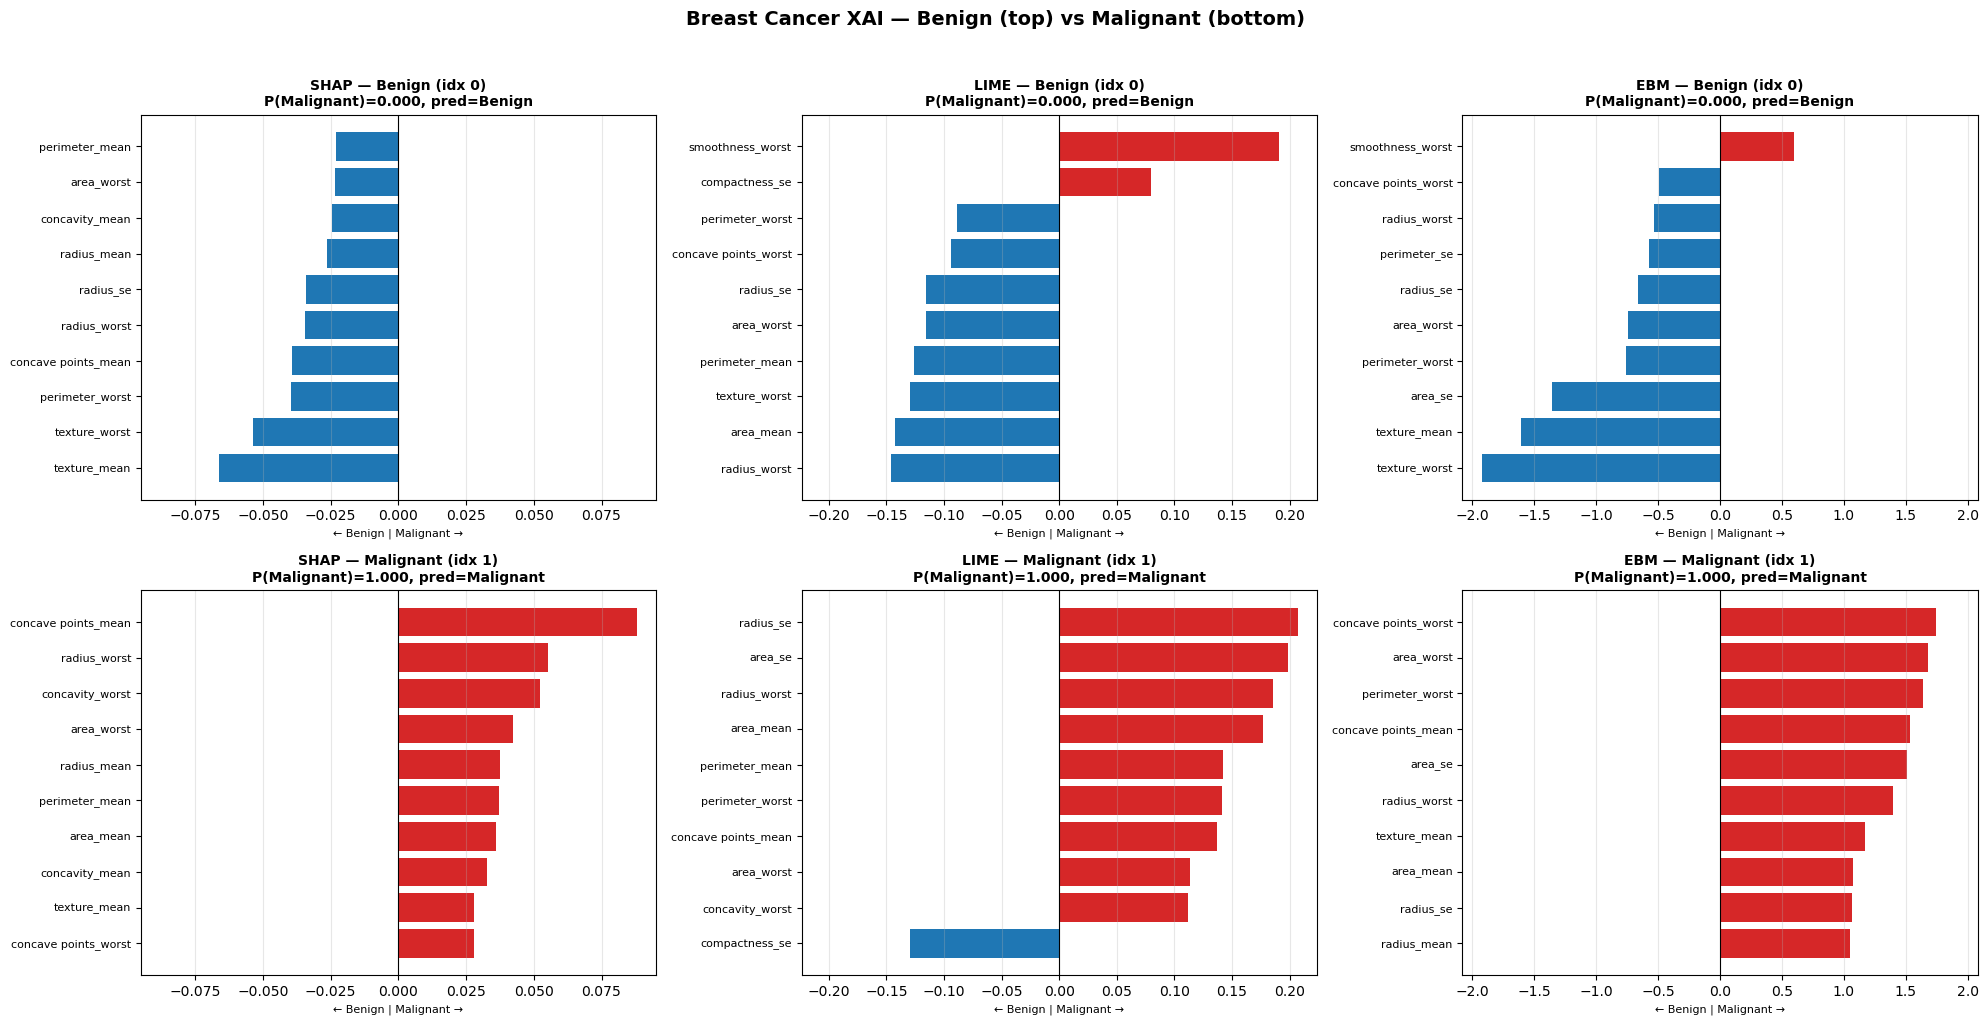

Saved. Share mode: column


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

TOP_N = 10          # <- top 10 features
SHARE_MODE = "column"   # "column" = same axis per method | "global" = same axis everywhere

def plot_pos_neg(attr, feature_names, title, ax, top_n=TOP_N, xlim=None):
    attr = np.asarray(attr).flatten()
    idx = np.argsort(np.abs(attr))[::-1][:top_n]
    idx = idx[np.argsort(attr[idx])]
    vals  = attr[idx]
    names = [feature_names[i] for i in idx]
    colors = ['#d62728' if v > 0 else '#1f77b4' for v in vals]
    ax.barh(range(len(vals)), vals, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(names, fontsize=8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel("← Benign | Malignant →", fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    if xlim is not None:
        ax.set_xlim(xlim)

methods = ["SHAP", "LIME", "EBM"]

# --- compute the x-axis limits ---
def symmetric_limit(values_list):
    """Symmetric [-M, +M] limit covering the top_n features of every vector."""
    m = 0.0
    for v in values_list:
        v = np.asarray(v).flatten()
        topvals = v[np.argsort(np.abs(v))[::-1][:TOP_N]]
        m = max(m, np.max(np.abs(topvals)))
    pad = m * 0.08
    return (-(m + pad), m + pad)

if SHARE_MODE == "column":
    # one limit per method, shared across the two class rows
    xlims = {meth: symmetric_limit([attributions[0][meth], attributions[1][meth]])
             for meth in methods}
elif SHARE_MODE == "global":
    g = symmetric_limit([attributions[c][m] for c in [0, 1] for m in methods])
    xlims = {meth: g for meth in methods}

# --- draw ---
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for row, cls in enumerate([0, 1]):
    p = lstm_predict_proba(samples[cls])[0]
    pred = int(p[1] > 0.5)
    for col, method in enumerate(methods):
        title = (f"{method} — {label_names[cls]} (idx {sample_idx[cls]})\n"
                 f"P(Malignant)={p[1]:.3f}, pred={label_names[pred]}")
        plot_pos_neg(attributions[cls][method], feature_names, title,
                     axes[row, col], xlim=xlims[method])

plt.suptitle("Breast Cancer XAI — Benign (top) vs Malignant (bottom)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("/home/aqsa/sok/breast_xai_both_classes.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved. Share mode: {SHARE_MODE}")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os

TOP_N = 10
SHARE_MODE = "column"          # "column" = shared axis per method | "global" = one axis everywhere
OUT_DIR = "/home/aqsa/sok/xai_plots"
os.makedirs(OUT_DIR, exist_ok=True)

methods = ["SHAP", "LIME", "EBM"]

# --- shared x-axis limits ---
def symmetric_limit(values_list):
    m = 0.0
    for v in values_list:
        v = np.asarray(v).flatten()
        topvals = v[np.argsort(np.abs(v))[::-1][:TOP_N]]
        m = max(m, np.max(np.abs(topvals)))
    pad = m * 0.08
    return (-(m + pad), m + pad)

if SHARE_MODE == "column":
    xlims = {meth: symmetric_limit([attributions[0][meth], attributions[1][meth]])
             for meth in methods}
else:  # "global"
    g = symmetric_limit([attributions[c][m] for c in [0, 1] for m in methods])
    xlims = {meth: g for meth in methods}

# --- single-panel plotter ---
def plot_single(attr, feature_names, title, xlim, save_path, top_n=TOP_N):
    attr = np.asarray(attr).flatten()
    idx = np.argsort(np.abs(attr))[::-1][:top_n]
    idx = idx[np.argsort(attr[idx])]
    vals  = attr[idx]
    names = [feature_names[i] for i in idx]
    colors = ['#d62728' if v > 0 else '#1f77b4' for v in vals]

    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.barh(range(len(vals)), vals, color=colors)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(names, fontsize=11)            # bigger feature labels
    ax.tick_params(axis='x', labelsize=10)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel("\u2190 Benign  |  Malignant \u2192", fontsize=11)  # bigger axis label
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.grid(axis='x', alpha=0.3)
    ax.set_xlim(xlim)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# --- generate all 6 individual plots ---
for cls in [0, 1]:
    gt = label_names[cls]
    p = lstm_predict_proba(samples[cls])[0]
    pred = label_names[int(p[1] > 0.5)]
    for method in methods:
        title = f"{method}  |  Ground Truth: {gt}  |  Prediction: {pred}"
        fname = f"breast_{method.lower()}_{gt.lower()}.png"
        save_path = os.path.join(OUT_DIR, fname)
        print(f"--- {fname} ---")
        plot_single(attributions[cls][method], feature_names, title,
                    xlims[method], save_path)

print(f"\nAll 6 plots saved to {OUT_DIR}/")